In [1]:
import pandas as pd

train = pd.read_csv("../data/fraudTrain.csv", index_col=0)
test  = pd.read_csv("../data/fraudTest.csv",  index_col=0)

df = pd.concat([train, test], ignore_index=True)
df["trans_date_trans_time"] = pd.to_datetime(df["trans_date_trans_time"])
df = df.sort_values("trans_date_trans_time").reset_index(drop=True)

print(df.shape)
print(df["trans_date_trans_time"].min(), "→", df["trans_date_trans_time"].max())
print("Taux de fraude :", df["is_fraud"].mean())
df.head()

(1852394, 22)
2019-01-01 00:00:18 → 2020-12-31 23:59:34
Taux de fraude : 0.005210014716091717


,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [2]:
print(df.dtypes)
print("\nValeurs manquantes :", df.isna().sum().sum())
print("\nNombre de cartes :", df["cc_num"].nunique())
print("Transactions par carte (médiane) :", df.groupby("cc_num").size().median())
print("\nFraudes :", df["is_fraud"].sum(), "sur", len(df))

trans_date_trans_time    datetime64[us]
cc_num                            int64
merchant                            str
category                            str
amt                             float64
first                               str
last                                str
gender                              str
street                              str
city                                str
state                               str
zip                               int64
lat                             float64
long                            float64
city_pop                          int64
job                                 str
dob                                 str
trans_num                           str
unix_time                         int64
merch_lat                       float64
merch_long                      float64
is_fraud                          int64
dtype: object

Valeurs manquantes : 0

Nombre de cartes : 999
Transactions par carte (médiane) : 1471.0

Fraudes : 9651 

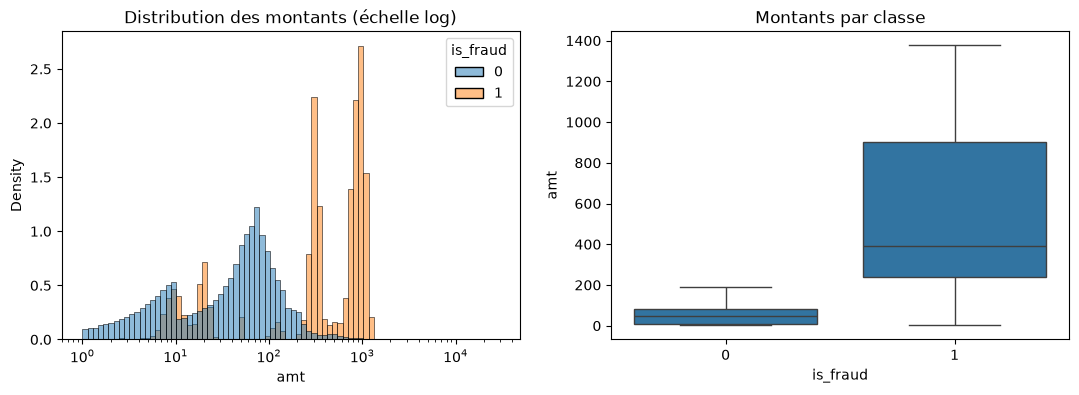

              count        mean         std   min      25%     50%      75%  \
is_fraud                                                                      
0         1842743.0   67.651278  153.548108  1.00    9.610   47.24   82.560   
1            9651.0  530.661412  391.028873  1.06  240.075  390.00  902.365   

               max  
is_fraud            
0         28948.90  
1          1376.04  


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x="amt", hue="is_fraud", bins=80, log_scale=True,
             stat="density", common_norm=False, ax=ax[0])
ax[0].set_title("Distribution des montants (échelle log)")
sns.boxplot(data=df, x="is_fraud", y="amt", showfliers=False, ax=ax[1])
ax[1].set_title("Montants par classe")
plt.show()

print(df.groupby("is_fraud")["amt"].describe())

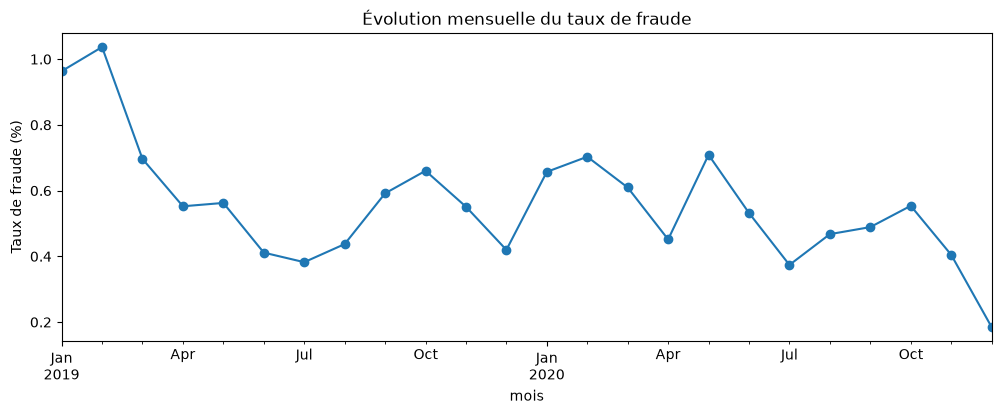

In [4]:
df["mois"] = df["trans_date_trans_time"].dt.to_period("M")
taux_mois = df.groupby("mois")["is_fraud"].mean() * 100

taux_mois.plot(figsize=(12, 4), marker="o")
plt.ylabel("Taux de fraude (%)")
plt.title("Évolution mensuelle du taux de fraude")
plt.show()

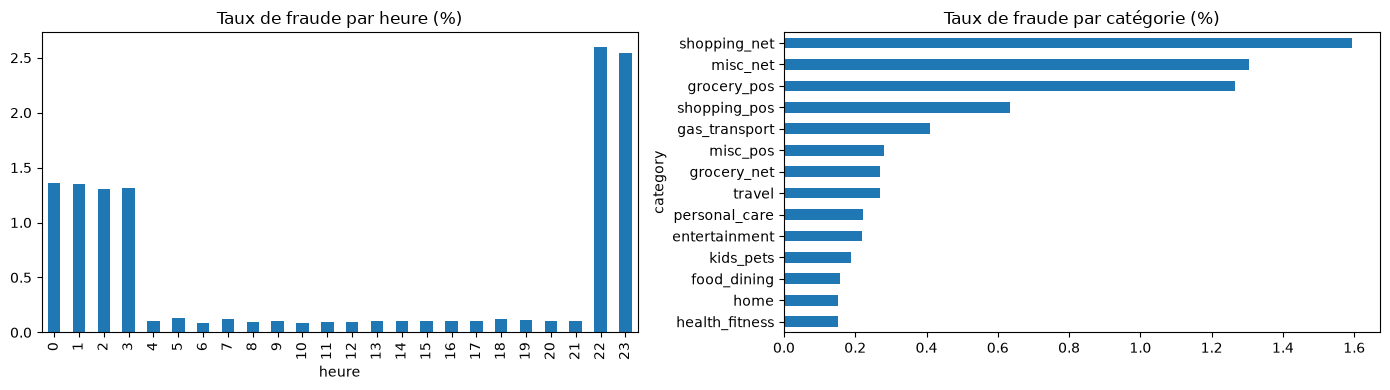

In [5]:
df["heure"] = df["trans_date_trans_time"].dt.hour

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
(df.groupby("heure")["is_fraud"].mean() * 100).plot(kind="bar", ax=ax[0])
ax[0].set_title("Taux de fraude par heure (%)")

(df.groupby("category")["is_fraud"].mean() * 100).sort_values().plot(kind="barh", ax=ax[1])
ax[1].set_title("Taux de fraude par catégorie (%)")
plt.tight_layout()
plt.show()

In [6]:
import sys
sys.path.append("..")
from src.features import build_features

feats = build_features(df)
print(feats.shape)

cols = ["amt", "tx_1h", "tx_24h", "amt_ratio_30d", "gap_prev_s", "dist_km", "age"]
feats.groupby("is_fraud")[cols].mean().T

(1852394, 16)


is_fraud,0,1
amt,67.651278,530.661412
tx_1h,0.197525,0.676925
tx_24h,4.109736,4.304839
amt_ratio_30d,1.031935,5.622610
gap_prev_s,32252.335494,45367.499845
dist_km,76.110969,76.256233
age,46.250415,48.834063


In [7]:
import numpy as np

n = len(feats)
i1, i2 = int(0.6 * n), int(0.8 * n)
train, val, test = feats.iloc[:i1], feats.iloc[i1:i2], feats.iloc[i2:]

for name, d in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:5s} {len(d):>8d} lignes | "
          f"{d['trans_date_trans_time'].min().date()} → {d['trans_date_trans_time'].max().date()} | "
          f"fraudes : {d['is_fraud'].sum():>5d} ({d['is_fraud'].mean()*100:.2f} %)")

train  1111436 lignes | 2019-01-01 → 2020-04-07 | fraudes :  6401 (0.58 %)
val     370479 lignes | 2020-04-07 → 2020-08-25 | fraudes :  1901 (0.51 %)
test    370479 lignes | 2020-08-25 → 2020-12-31 | fraudes :  1349 (0.36 %)


In [8]:
from sklearn.preprocessing import StandardScaler

num_cols = ["log_amt", "hour_sin", "hour_cos", "dayofweek", "tx_1h", "tx_24h",
            "amt_ratio_30d", "gap_prev_s", "dist_km", "age", "log_city_pop"]
cats = sorted(feats["category"].unique())

def to_matrix(d):
    X = d[num_cols].copy()
    X["gap_prev_s"] = np.log1p(X["gap_prev_s"])
    for c in cats:
        X[f"cat_{c}"] = (d["category"] == c).astype("float32")
    return X

X_tr, X_va, X_te = to_matrix(train), to_matrix(val), to_matrix(test)
y_tr, y_va, y_te = train["is_fraud"].values, val["is_fraud"].values, test["is_fraud"].values

scaler = StandardScaler().fit(X_tr)          # statistiques du train seulement
Xs_tr, Xs_va, Xs_te = (scaler.transform(m).astype("float32") for m in (X_tr, X_va, X_te))

In [9]:
from sklearn.ensemble import IsolationForest
from src.evaluate import report

if_all = IsolationForest(n_estimators=200, max_samples=256, random_state=42, n_jobs=-1)
if_all.fit(Xs_tr)
score_va = -if_all.score_samples(Xs_va)      # plus grand = plus anormal

K = 1000   
print(report(y_va, score_va, K))

{'PR-AUC': 0.0703135732436789, 'ROC-AUC': 0.8340736657561348, 'precision@1000': np.float64(0.16), 'recall@1000': np.float64(0.08416622830089426)}


In [10]:
print((feats["gap_prev_s"] < 0).sum(), "écarts négatifs")
print(X_tr.isna().sum()[lambda s: s > 0])

0 écarts négatifs
Series([], dtype: int64)


In [12]:
from sklearn.ensemble import IsolationForest
from src.evaluate import report

K = 1000

# A : entraîné sur tout le train, sans utiliser les étiquettes
if_a = IsolationForest(n_estimators=200, max_samples=256, random_state=42, n_jobs=-1)
if_a.fit(Xs_tr)
score_a = -if_a.score_samples(Xs_va)

# B : entraîné sur les transactions normales seulement
if_b = IsolationForest(n_estimators=200, max_samples=256, random_state=42, n_jobs=-1)
if_b.fit(Xs_tr[y_tr == 0])
score_b = -if_b.score_samples(Xs_va)

import pandas as pd
pd.DataFrame({"A (tout le train)": report(y_va, score_a, K),
              "B (normales seules)": report(y_va, score_b, K)}).T

,PR-AUC,ROC-AUC,precision@1000,recall@1000
A (tout le train),0.070314,0.834074,0.160,0.084166
B (normales seules),0.067650,0.827925,0.164,0.086270


In [13]:
import numpy as np
from sklearn.neural_network import MLPRegressor

rng = np.random.default_rng(42)
idx = rng.choice(len(Xs_tr), size=300_000, replace=False)   # sous-échantillon pour la vitesse
X_ae = Xs_tr[idx]

ae = MLPRegressor(hidden_layer_sizes=(16, 6, 16), activation="relu",
                  max_iter=30, early_stopping=True, random_state=42)
ae.fit(X_ae, X_ae)          # la cible est l'entrée elle-même

def ae_score(X):
    return ((X - ae.predict(X)) ** 2).mean(axis=1)    # erreur de reconstruction

score_ae = ae_score(Xs_va)
pd.DataFrame({"IsolationForest (A)": report(y_va, score_a, K),
              "Autoencodeur": report(y_va, score_ae, K)}).T

.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


,PR-AUC,ROC-AUC,precision@1000,recall@1000
IsolationForest (A),0.070314,0.834074,0.160,0.084166
Autoencodeur,0.057654,0.785980,0.121,0.063651


In [14]:
from xgboost import XGBClassifier

ratio = (y_tr == 0).sum() / (y_tr == 1).sum()

def fit_xgb(spw):
    m = XGBClassifier(n_estimators=500, max_depth=6, learning_rate=0.05,
                      subsample=0.8, colsample_bytree=0.8,
                      scale_pos_weight=spw, tree_method="hist",
                      eval_metric="aucpr", early_stopping_rounds=30,
                      random_state=42, n_jobs=-1)
    m.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    return m

xgb_plain = fit_xgb(1)                 # sans correction
xgb_w     = fit_xgb(ratio ** 0.5)      # pondération atténuée (racine du ratio)

score_x_plain = xgb_plain.predict_proba(X_va)[:, 1]
score_x_w     = xgb_w.predict_proba(X_va)[:, 1]

pd.DataFrame({
    "XGB sans poids": report(y_va, score_x_plain, K),
    "XGB pondéré":    report(y_va, score_x_w, K),
}).T

,PR-AUC,ROC-AUC,precision@1000,recall@1000
XGB sans poids,0.943755,0.998891,0.999,0.525513
XGB pondéré,0.943463,0.998961,0.998,0.524987


k = 1852


PR-AUC  ROC-AUC  precision@1852  recall@1852
Isolation Forest val    0.070    0.834           0.139        0.135
                 test   0.029    0.813           0.057        0.078
Autoencodeur     val    0.058    0.786           0.152        0.148
                 test   0.026    0.761           0.062        0.085
XGBoost          val    0.944    0.999           0.897        0.874
                 test   0.930    0.999           0.678        0.931

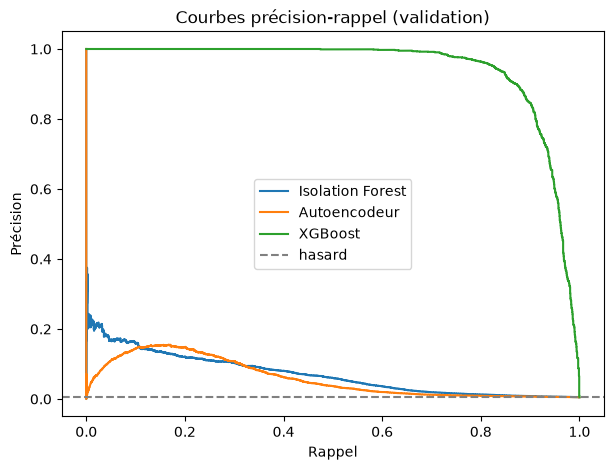

In [16]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve
from src.evaluate import report

K = int(0.005 * len(y_va))     # budget : 0,5 % du volume (idem pour le test, mêmes tailles)
print("k =", K)

model = xgb_plain              # modèle retenu
scores = {
    "Isolation Forest": (-if_a.score_samples(Xs_va), -if_a.score_samples(Xs_te)),
    "Autoencodeur":     (ae_score(Xs_va),            ae_score(Xs_te)),
    "XGBoost":          (model.predict_proba(X_va)[:, 1], model.predict_proba(X_te)[:, 1]),
}

rows = {}
for name, (sv, st) in scores.items():
    rows[(name, "val")]  = report(y_va, sv, K)
    rows[(name, "test")] = report(y_te, st, K)
display(pd.DataFrame(rows).T.round(3))

plt.figure(figsize=(7, 5))
for name, (sv, _) in scores.items():
    p, r, _ = precision_recall_curve(y_va, sv)
    plt.plot(r, p, label=name)
plt.axhline(y_va.mean(), ls="--", c="gray", label="hasard")
plt.xlabel("Rappel"); plt.ylabel("Précision"); plt.title("Courbes précision-rappel (validation)")
plt.legend(); plt.show()

In [18]:
from sklearn.metrics import fbeta_score, matthews_corrcoef

C_ALERT = 5.0
amt_va, amt_te = val["amt"].values, test["amt"].values
sv, st = scores["XGBoost"]

def best_threshold(y, score, amt, c_alert):
    order = np.argsort(-score)
    fraud_amt = (amt * y)[order]
    caught = np.concatenate([[0.0], np.cumsum(fraud_amt)])
    cost = (fraud_amt.sum() - caught) + c_alert * np.arange(len(y) + 1)
    n = int(np.argmin(cost))
    thr = score[order][n - 1] if n > 0 else np.inf
    return thr, cost[n], cost[0]

def evaluate_at(y, score, amt, thr, c_alert):
    alert = score >= thr
    missed = (amt * y * ~alert).sum()
    return {"alertes": int(alert.sum()),
            "précision": y[alert].mean() if alert.any() else 0,
            "rappel": y[alert].sum() / y.sum(),
            "F2": fbeta_score(y, alert, beta=2),
            "MCC": matthews_corrcoef(y, alert),
            "coût": missed + c_alert * alert.sum(),
            "coût sans modèle": (amt * y).sum()}

thr, cost_min, _ = best_threshold(y_va, sv, amt_va, C_ALERT)
print(f"Seuil retenu (validation) : {thr:.4f}")
pd.DataFrame({"validation": evaluate_at(y_va, sv, amt_va, thr, C_ALERT),
              "test": evaluate_at(y_te, st, amt_te, thr, C_ALERT)}).round(3)

Seuil retenu (validation) : 0.0203


,validation,test
alertes,3754.000,3053.000
précision,0.487,0.425
rappel,0.963,0.963
F2,0.806,0.769
MCC,0.683,0.638
coût,31036.050,22793.360
coût sans modèle,989313.460,733911.720


Module 5:Explicabilité avec SHAP

.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


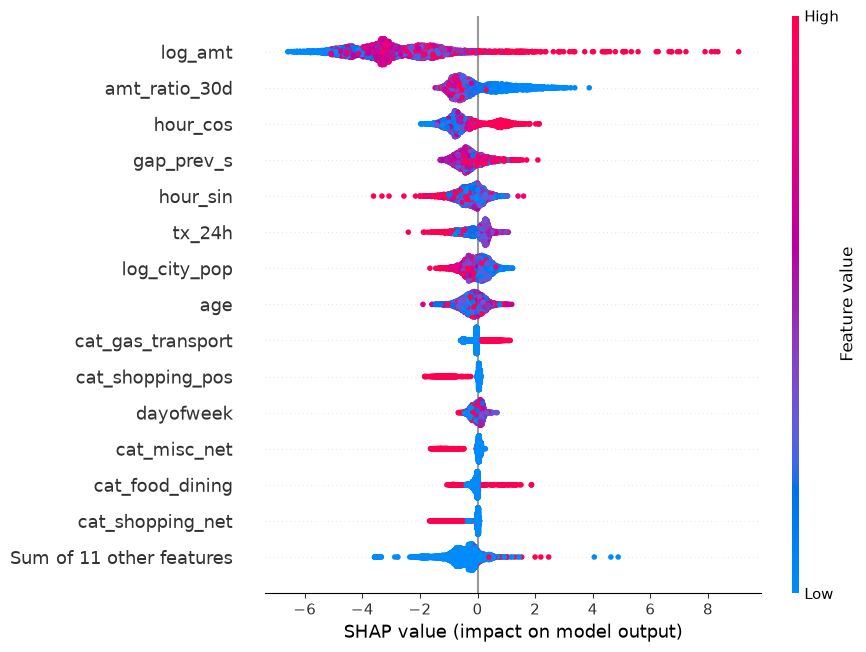

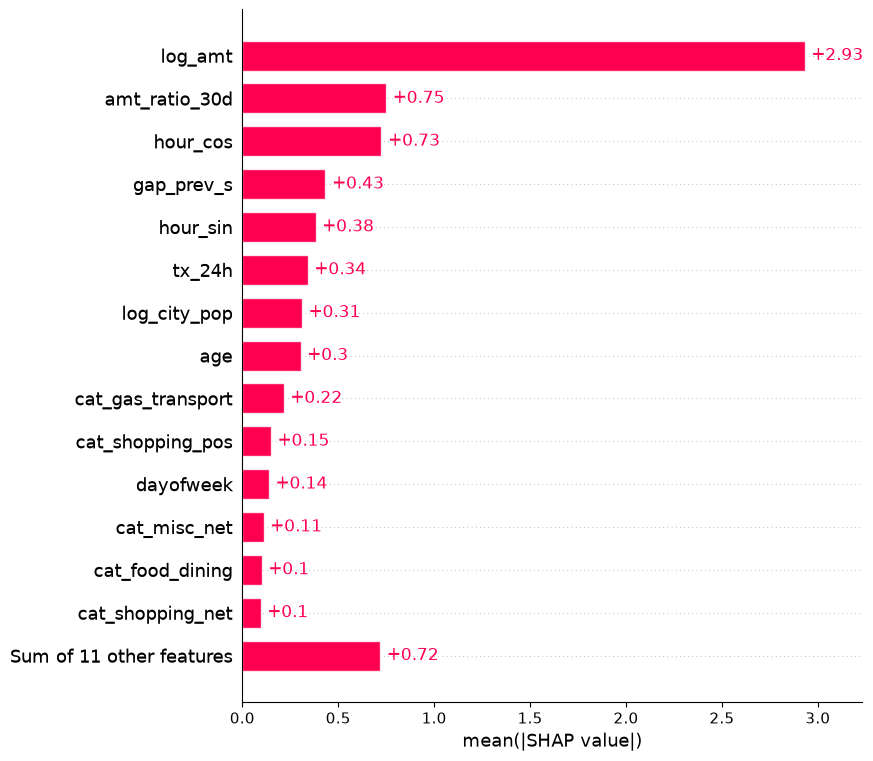

In [19]:
import shap

explainer = shap.TreeExplainer(xgb_plain)

rng = np.random.default_rng(0)
samp = rng.choice(len(X_te), size=5000, replace=False)
shap_exp = explainer(X_te.iloc[samp])

shap.plots.beeswarm(shap_exp, max_display=15)
shap.plots.bar(shap_exp, max_display=15)     # importance moyenne absolue

Transaction 108 | score = 0.995 | montant = 304.82 $


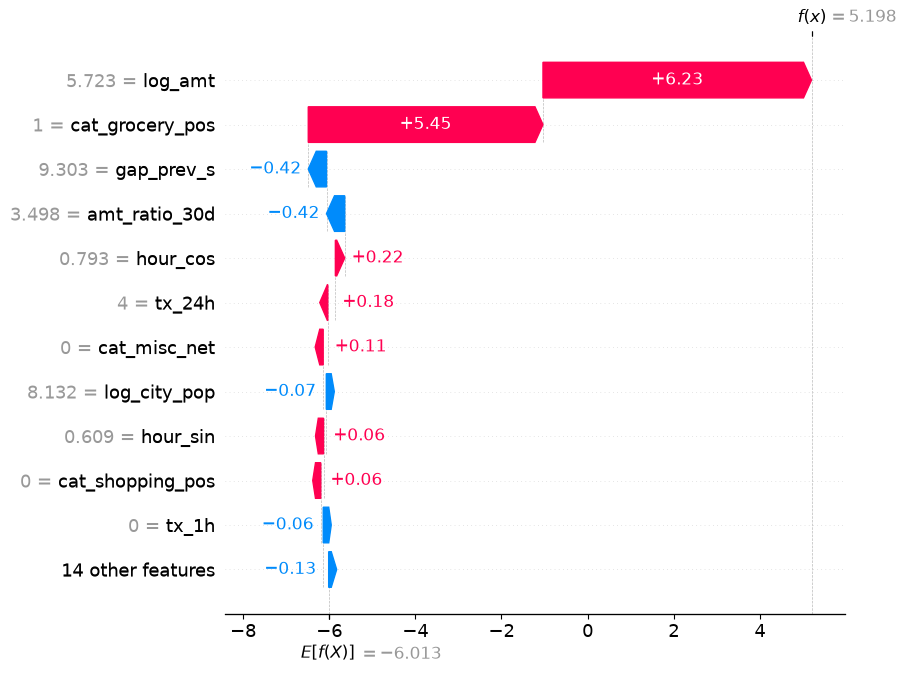

In [20]:
p_te = xgb_plain.predict_proba(X_te)[:, 1]
# première vraie fraude au-dessus du seuil retenu
i = np.where((p_te >= thr) & (y_te == 1))[0][0]

print(f"Transaction {i} | score = {p_te[i]:.3f} | montant = {test['amt'].iloc[i]:.2f} $")
shap.plots.waterfall(explainer(X_te.iloc[[i]])[0], max_display=12)

In [21]:
def reason_codes(row, top=4):
    """row : DataFrame d'une seule ligne (mêmes colonnes que X_te)."""
    e = explainer(row)
    contrib = e.values[0]
    order = np.argsort(-contrib)[:top]
    return [(row.columns[j], float(row.iloc[0, j]), round(float(contrib[j]), 3))
            for j in order if contrib[j] > 0]

for name, val, c in reason_codes(X_te.iloc[[i]]):
    print(f"{name:20s} valeur = {val:10.3f}   contribution = {c:+.3f}")

log_amt              valeur =      5.723   contribution = +6.235
cat_grocery_pos      valeur =      1.000   contribution = +5.450
hour_cos             valeur =      0.793   contribution = +0.217
tx_24h               valeur =      4.000   contribution = +0.177


In [23]:
import joblib, json, os
os.makedirs("../artifacts", exist_ok=True)

# 1. Modèle
joblib.dump(xgb_plain, "../artifacts/xgb.joblib")

# 2. Métadonnées : variables, seuil, coût d'alerte
meta = {"features": list(X_tr.columns), "threshold": float(thr),
        "c_alert": 5.0, "k_ratio": 0.005}
json.dump(meta, open("../artifacts/meta.json", "w"), indent=2)

# 3. Test avec scores de tous les modèles, pour les curseurs de l'appli
app_df = X_te.copy()
app_df["amt"] = test["amt"].values
app_df["is_fraud"] = y_te
app_df["date"] = test["trans_date_trans_time"].values
app_df["cc_num"] = test["cc_num"].values
app_df["score_xgb"] = scores["XGBoost"][1]
app_df["score_iforest"] = scores["Isolation Forest"][1]
app_df["score_ae"] = scores["Autoencodeur"][1]
app_df.to_parquet("../artifacts/test_scored.parquet")
print(app_df.shape)

(370479, 32)
